# 02. 특성 공학 파이프라인 · 변수 선택 · 모델 학습/평가 · 실험 비교

**평가 설계**
- `train.csv`(891행)를 Stratified 80:20으로 분할 → train 712행 / test 179행
- 모든 비교 실험은 **train에서 Stratified 5-Fold CV**(평균 ± 표준편차)로 수행하고, test는 최종 평가에만 사용
- 모든 전처리(결측치 대체·인코딩·스케일링·변수 선택)는 `sklearn.Pipeline` 내부에서 fold마다 fit → 데이터 누수 방지
- 주 지표: **F1-score** (타겟 61.6:38.4 약한 불균형) / 보조 지표: ROC-AUC, Accuracy, Precision, Recall
- 과적합 지표: `Gap = train Accuracy − validation Accuracy` (CV 기준)

In [1]:
import sys, os, time, warnings
sys.path.append(os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance
from src.fe_pipeline import (add_features, build_pipeline, build_base_pipeline, MODEL_NAMES,
                             RANDOM_STATE, TARGET, to_raw, get_native_model)

FIG, RES = "../results/figures", "../results"
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

df = add_features(pd.read_csv("../data/train.csv"))
X, y = df.drop(columns=[TARGET]), df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, "test:", X_test.shape, "| train 생존율:", round(y_train.mean(), 3))

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]


def cv_eval(pipe, Xt=None, yt=None):
    Xt = X_train if Xt is None else Xt
    yt = y_train if yt is None else yt
    r = cross_validate(pipe, Xt, yt, cv=CV, scoring=SCORING, return_train_score=True, n_jobs=-1)
    out = {}
    for m in SCORING:
        out[m] = r[f"test_{m}"].mean(); out[f"{m}_std"] = r[f"test_{m}"].std()
    out["train_acc"] = r["train_accuracy"].mean()
    out["gap"] = out["train_acc"] - out["accuracy"]
    out["n_features"] = None
    return out


def n_features_after(pipe):
    p = pipe.fit(X_train, y_train)
    Z = p[:-1].transform(X_train.iloc[:5])
    return Z.shape[1]


all_rows = []   # 모든 실험 결과를 하나의 긴 표로 누적


def run(group, name, builder, models=MODEL_NAMES, Xt=None, yt=None, **kw):
    rows = []
    for m in models:
        pipe = builder(m, **kw) if kw else builder(m)
        r = cv_eval(pipe, Xt, yt)
        r.update({"group": group, "experiment": name, "model": m})
        rows.append(r)
    all_rows.extend(rows)
    return pd.DataFrame(rows)


def show(d, cols=("experiment", "model", "f1", "f1_std", "roc_auc", "accuracy", "gap")):
    return d[list(cols)].round(4)

train: (712, 16) test: (179, 16) | train 생존율: 0.383


## STEP 03. 특성 공학 비교 실험 (한 번에 한 요소만 변경하는 Ablation)
기준 설정 = Exp-1 (Mean 대체 / One-Hot / Standard / 변수 선택 없음 / 파생 변수 사용)

### 3-1. 결측치 처리 비교: Mean vs Median vs Most Frequent vs Drop NA

In [2]:
t0 = time.time()
imp_res = pd.concat([run("3-1 Imputation", f"Impute={s}", build_pipeline, impute=s, encode="onehot",
                         scale="standard") for s in ["mean", "median", "most_frequent"]])
# Drop NA: Age·Embarked 결측 행을 train에서 제거한 뒤 동일 파이프라인으로 CV (행 수가 달라짐에 유의)
mask = X_train["Age"].notna() & X_train["Embarked"].notna()
print(f"Drop NA: train {len(X_train)} -> {mask.sum()} 행 ({(~mask).sum()}행, {(~mask).mean()*100:.1f}% 제거)")
drop_res = run("3-1 Imputation", "Impute=dropna", build_pipeline, Xt=X_train[mask], yt=y_train[mask],
               impute="none", encode="onehot", scale="standard")
imp_res = pd.concat([imp_res, drop_res])
show(imp_res)

Drop NA: train 712 -> 573 행 (139행, 19.5% 제거)


,experiment,model,f1,f1_std,roc_auc,accuracy,gap
0,Impute=mean,LogReg,0.7639,0.0337,0.8674,0.8202,0.0130
1,Impute=mean,RandomForest,0.7588,0.0378,0.8733,0.8189,0.1699
2,Impute=mean,XGBoost,0.7682,0.0300,0.8959,0.8273,0.1183
3,Impute=mean,LightGBM,0.7599,0.0277,0.8888,0.8231,0.1443
0,Impute=median,LogReg,0.7674,0.0345,0.8674,0.8230,0.0116
1,Impute=median,RandomForest,0.7677,0.0324,0.8762,0.8259,0.1604
2,Impute=median,XGBoost,0.7712,0.0326,0.8984,0.8301,0.1134
3,Impute=median,LightGBM,0.7551,0.0236,0.8898,0.8175,0.1492
0,Impute=most_frequent,LogReg,0.7652,0.0316,0.8673,0.8216,0.0109
1,Impute=most_frequent,RandomForest,0.7548,0.0322,0.8734,0.8161,0.1720


### 3-2. 범주형 인코딩 비교: One-Hot vs Label(Ordinal) vs Target Encoding
Target Encoding은 범주를 그 범주의 (평활화된) 생존율로 바꾼다. sklearn `TargetEncoder`는 fit 시 내부 cross-fitting을 하므로 타겟 누수가 없다.

In [3]:
enc_res = pd.concat([run("3-2 Encoding", f"Encode={e}", build_pipeline, impute="mean", encode=e,
                         scale="standard") for e in ["onehot", "label", "target"]])
for e in ["onehot", "label", "target"]:
    print(e, "-> 인코딩 후 특성 수:", n_features_after(build_pipeline("LogReg", encode=e)))
show(enc_res)

onehot -> 인코딩 후 특성 수: 24
label -> 인코딩 후 특성 수: 13
target -> 인코딩 후 특성 수: 13


,experiment,model,f1,f1_std,roc_auc,accuracy,gap
0,Encode=onehot,LogReg,0.7639,0.0337,0.8674,0.8202,0.0130
1,Encode=onehot,RandomForest,0.7588,0.0378,0.8733,0.8189,0.1699
2,Encode=onehot,XGBoost,0.7682,0.0300,0.8959,0.8273,0.1183
3,Encode=onehot,LightGBM,0.7599,0.0277,0.8888,0.8231,0.1443
0,Encode=label,LogReg,0.7408,0.0194,0.8578,0.8020,0.0088
1,Encode=label,RandomForest,0.7615,0.0315,0.8764,0.8217,0.1671
2,Encode=label,XGBoost,0.7626,0.0255,0.8917,0.8245,0.1204
3,Encode=label,LightGBM,0.7528,0.0342,0.8825,0.8147,0.1541
0,Encode=target,LogReg,0.7583,0.0241,0.8665,0.8132,0.0088
1,Encode=target,RandomForest,0.7851,0.0292,0.8817,0.8427,0.0870


### 3-3. 스케일링 비교: None vs Standard vs MinMax vs Robust

In [4]:
sc_res = pd.concat([run("3-3 Scaling", f"Scale={s}", build_pipeline, impute="mean", encode="onehot",
                        scale=s) for s in [None, "standard", "minmax", "robust"]])
show(sc_res)

,experiment,model,f1,f1_std,roc_auc,accuracy,gap
0,Scale=None,LogReg,0.7680,0.0293,0.8673,0.8244,0.0098
1,Scale=None,RandomForest,0.7559,0.0365,0.8730,0.8161,0.1727
2,Scale=None,XGBoost,0.7682,0.0300,0.8959,0.8273,0.1183
3,Scale=None,LightGBM,0.7545,0.0249,0.8874,0.8189,0.1499
0,Scale=standard,LogReg,0.7639,0.0337,0.8674,0.8202,0.0130
1,Scale=standard,RandomForest,0.7588,0.0378,0.8733,0.8189,0.1699
2,Scale=standard,XGBoost,0.7682,0.0300,0.8959,0.8273,0.1183
3,Scale=standard,LightGBM,0.7599,0.0277,0.8888,0.8231,0.1443
0,Scale=minmax,LogReg,0.7755,0.0310,0.8716,0.8287,0.0081
1,Scale=minmax,RandomForest,0.7550,0.0356,0.8724,0.8161,0.1727


### 3-4. 파생 변수 효과: 파생 변수 미사용 vs 사용
파생 변수 6개: FamilySize, IsAlone, FarePerPerson, HasCabin, Title, AgeGroup

In [5]:
fe_res = pd.concat([run("3-4 Feature Eng.", f"FE={u}", build_pipeline, impute="mean", encode="onehot",
                        scale="standard", use_fe=u) for u in [False, True]])
show(fe_res)
print(f"elapsed {time.time()-t0:.1f}s")

elapsed 26.9s


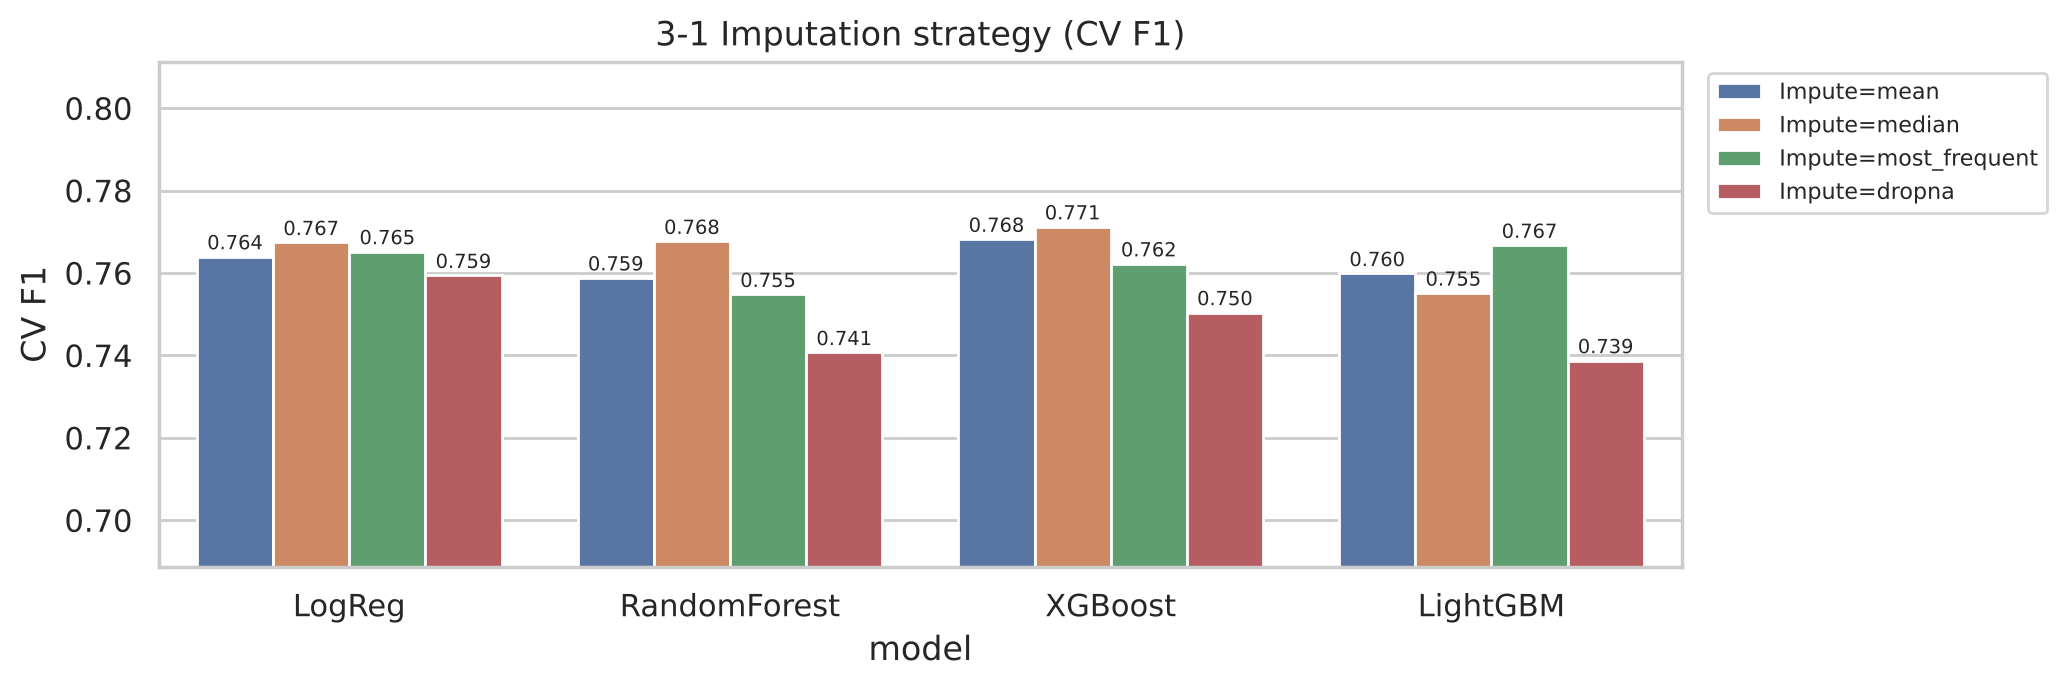

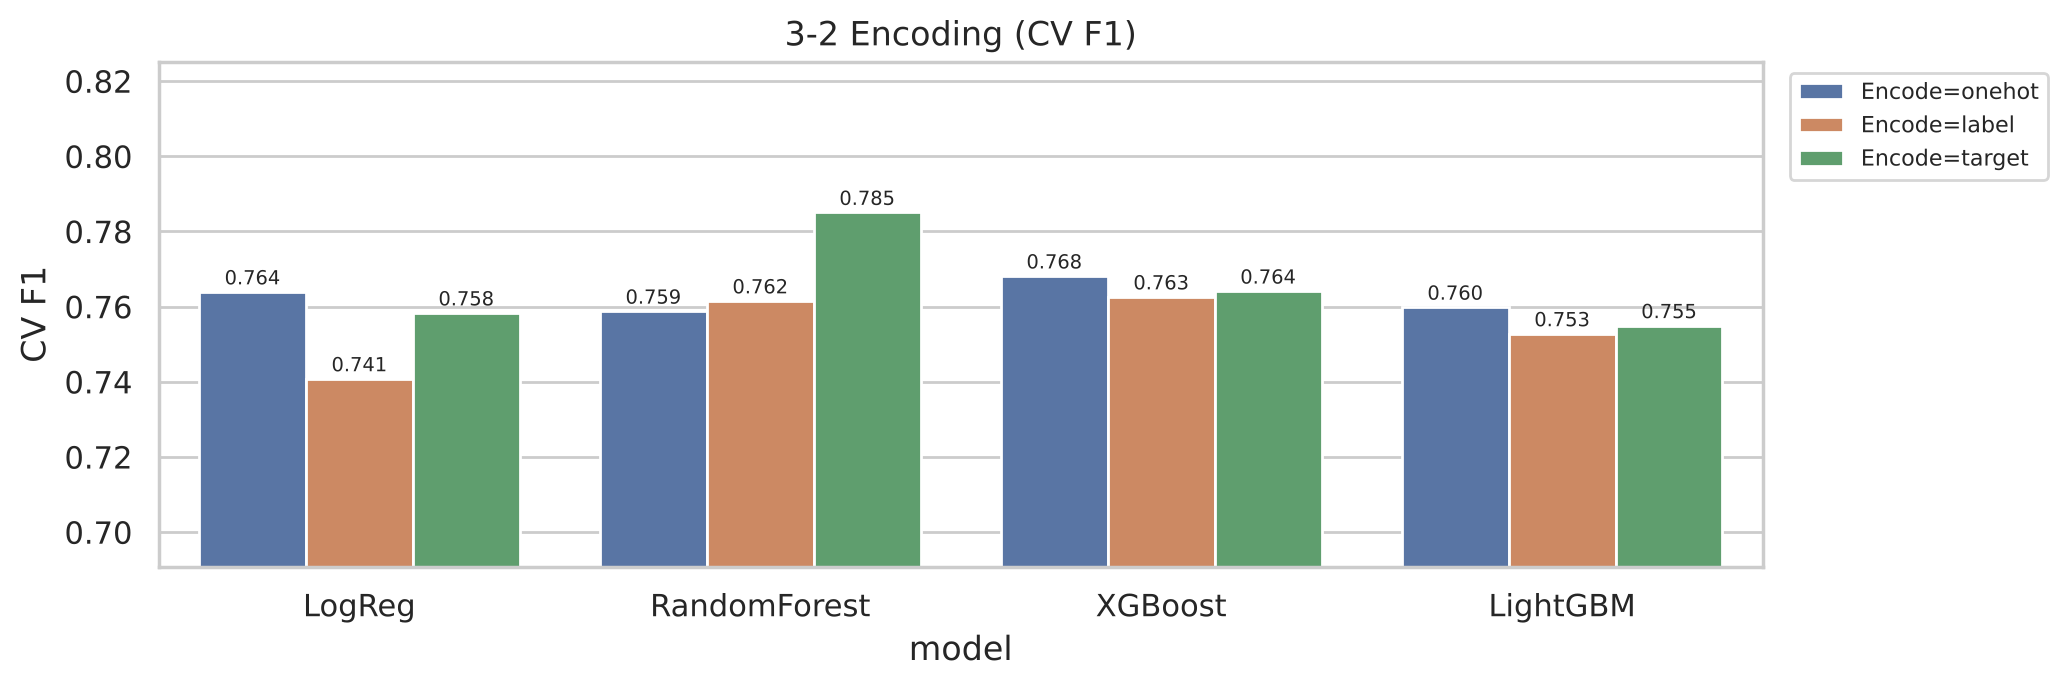

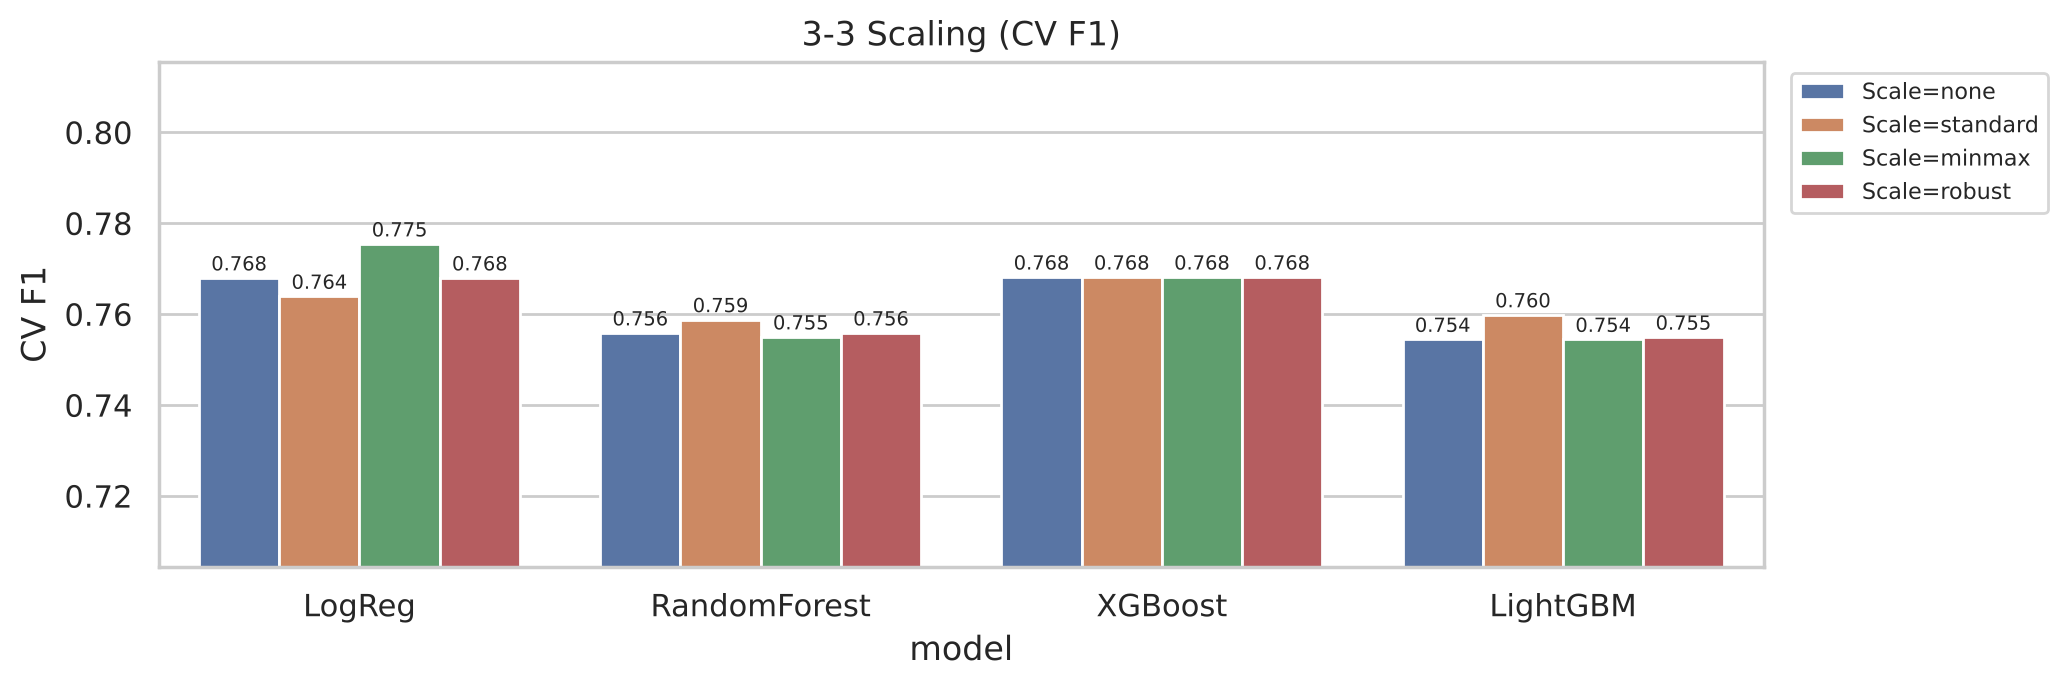

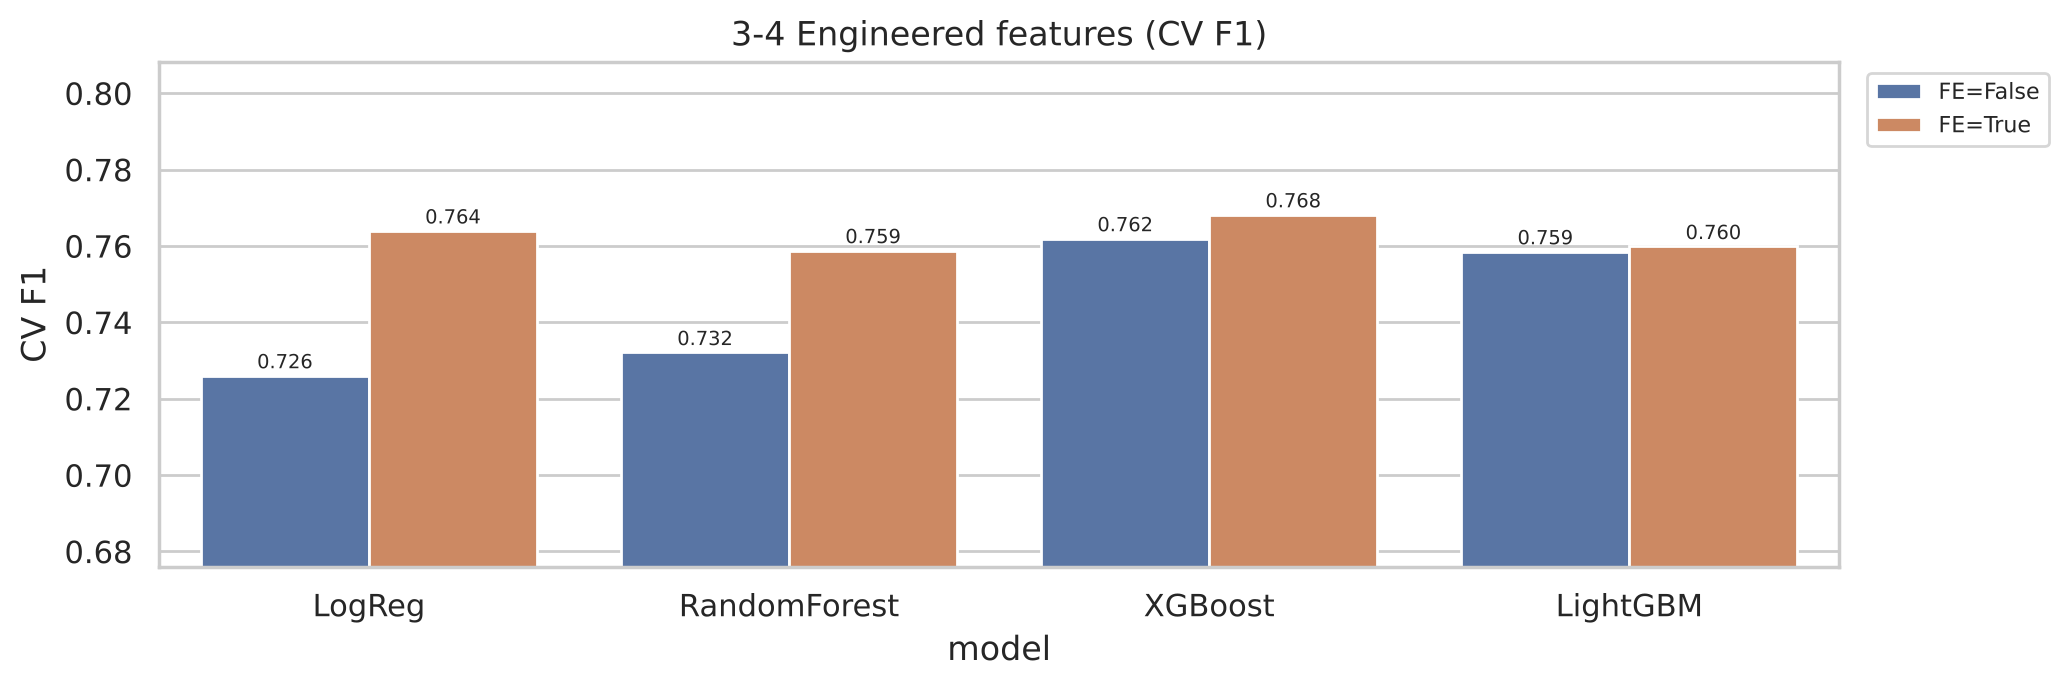

In [6]:
def grouped_bar(d, title, fname, metric="f1"):
    fig, ax = plt.subplots(figsize=(10.5, 3.6))
    sns.barplot(data=d, x="model", y=metric, hue="experiment", ax=ax)
    lo = d[metric].min() - 0.05; ax.set_ylim(max(0, lo), min(1, d[metric].max() + 0.04))
    ax.set_title(title); ax.set_ylabel(f"CV {metric.upper()}"); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=7, padding=1)
    plt.tight_layout(); plt.savefig(f"{FIG}/{fname}", dpi=150); plt.show()

grouped_bar(imp_res, "3-1 Imputation strategy (CV F1)", "10_imputation.png")
grouped_bar(enc_res, "3-2 Encoding (CV F1)", "11_encoding.png")
grouped_bar(sc_res.assign(experiment=sc_res.experiment.str.replace("None", "none")),
            "3-3 Scaling (CV F1)", "12_scaling.png")
grouped_bar(fe_res, "3-4 Engineered features (CV F1)", "13_feature_engineering.png")

## STEP 04. 변수 선택 (Random Forest Feature Importance 기반 SelectFromModel)
### (1) 전체 특성 중요도 (Exp-3 전처리: Most Frequent / One-Hot / Robust)

전체 특성 수: 24


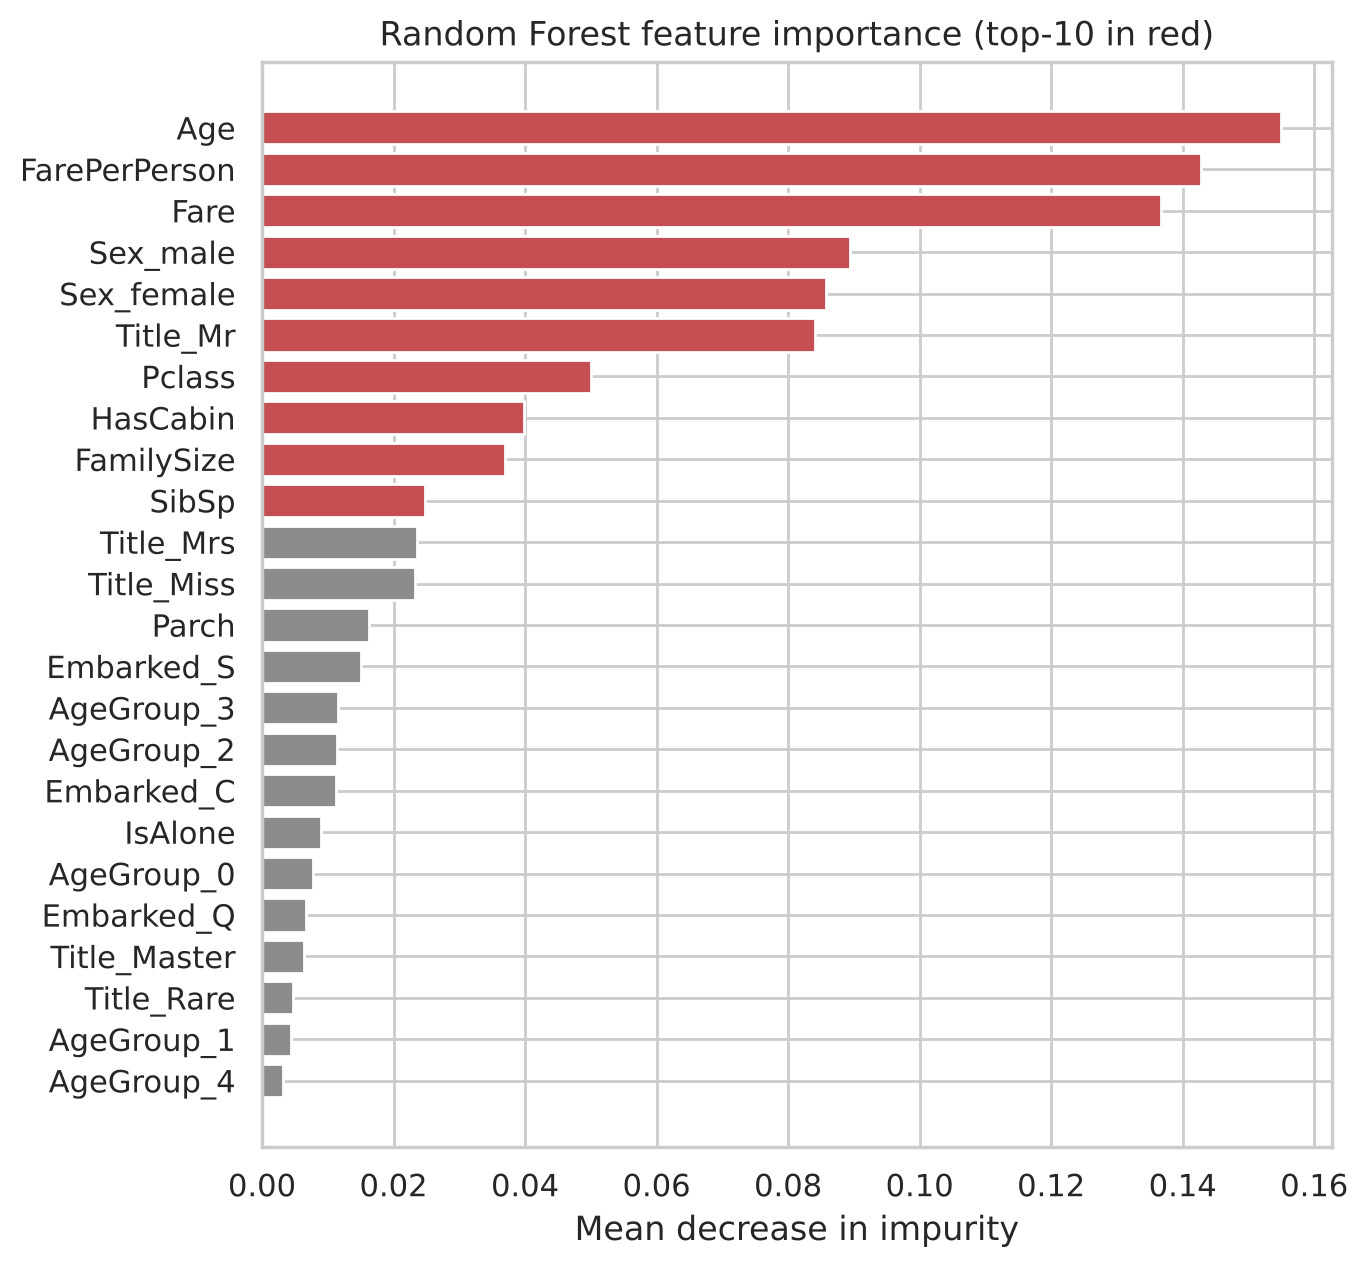

Age              0.1549
FarePerPerson    0.1427
Fare             0.1368
Sex_male         0.0894
Sex_female       0.0858
Title_Mr         0.0841
Pclass           0.0500
HasCabin         0.0399
FamilySize       0.0370
SibSp            0.0248
Title_Mrs        0.0236
Title_Miss       0.0233
dtype: float64

In [7]:
pipe_all = build_pipeline("RandomForest", impute="most_frequent", encode="onehot", scale="robust").fit(X_train, y_train)
feat_names = [n.split("__", 1)[1] for n in pipe_all[:-1].get_feature_names_out()]
imp = pd.Series(pipe_all[-1].feature_importances_, index=feat_names).sort_values(ascending=False)
imp.round(4).to_csv(f"{RES}/rf_feature_importance.csv", header=["importance"])
print("전체 특성 수:", len(imp))
fig, ax = plt.subplots(figsize=(7, 6.5))
colors = ["#C44E52" if i < 10 else "#8C8C8C" for i in range(len(imp))]
ax.barh(imp.index[::-1], imp.values[::-1], color=colors[::-1])
ax.set_title("Random Forest feature importance (top-10 in red)"); ax.set_xlabel("Mean decrease in impurity")
plt.tight_layout(); plt.savefig(f"{FIG}/20_rf_importance.png", dpi=150); plt.show()
imp.head(12).round(4)

### (2) 상위 N개 결정: N에 따른 CV 성능 곡선

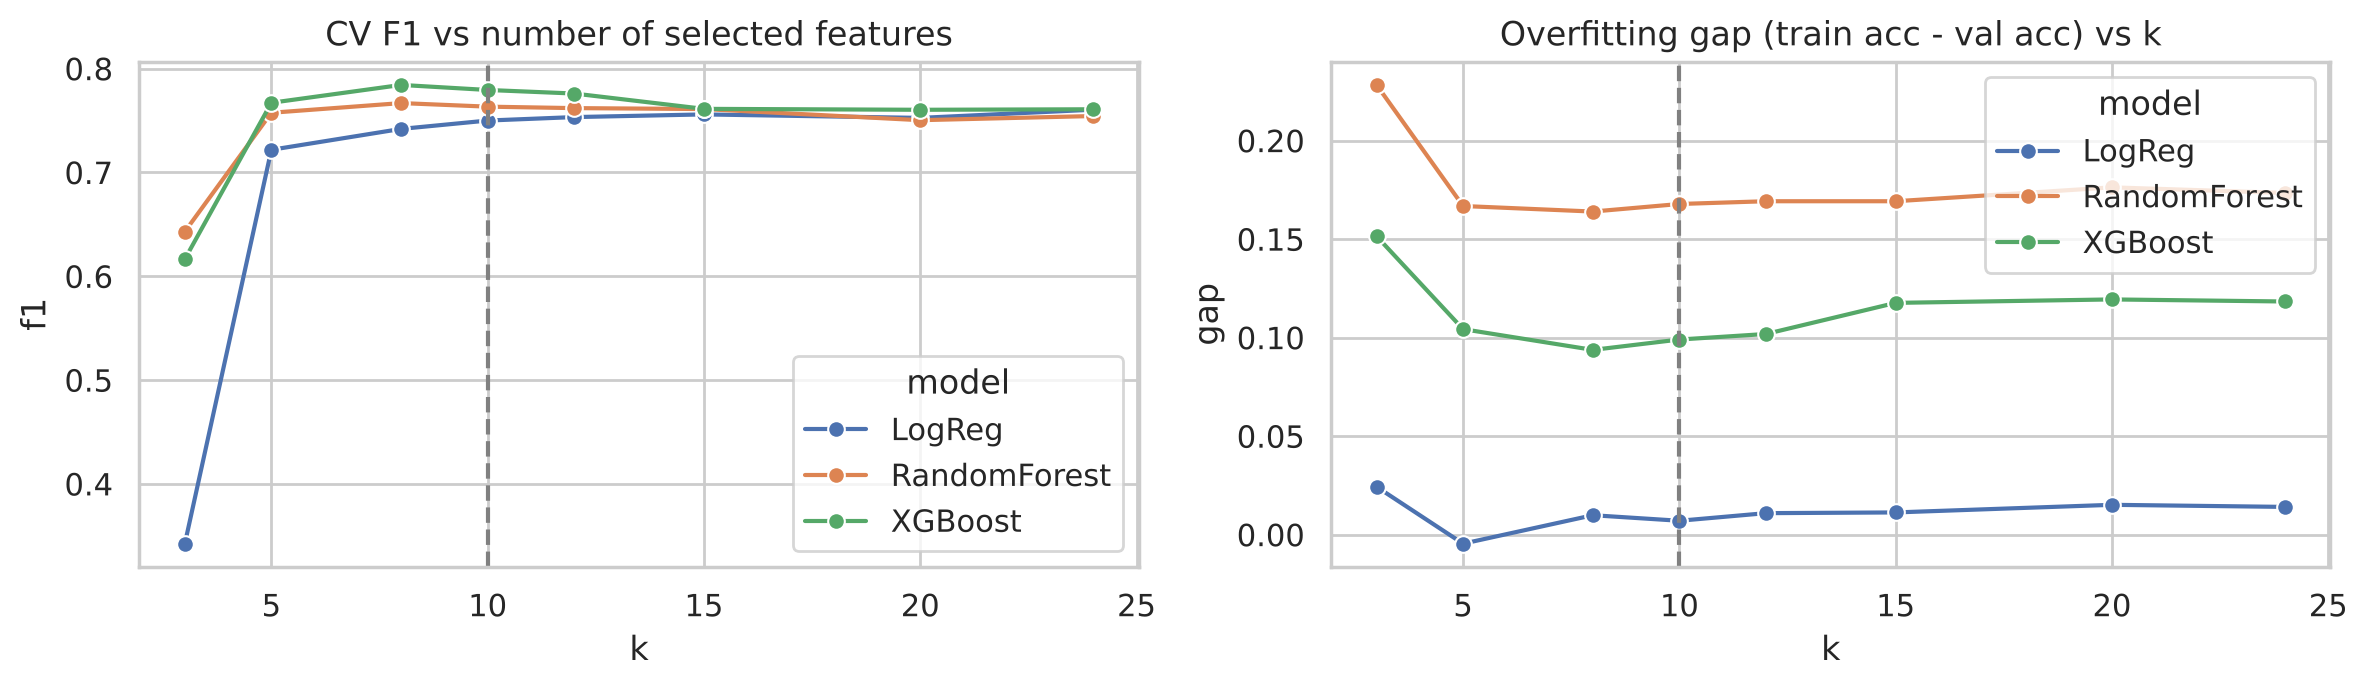

model,LogReg,RandomForest,XGBoost
k,,,
3,0.3423,0.6430,0.6165
5,0.7218,0.7574,0.7671
8,0.7419,0.7667,0.7842
10,0.7499,0.7633,0.7794
12,0.7533,0.7619,0.7759
15,0.7558,0.7610,0.7612
20,0.7525,0.7503,0.7603
24,0.7604,0.7543,0.7608


In [8]:
ks = [3, 5, 8, 10, 12, 15, 20, len(imp)]
curve = []
for m in ["LogReg", "RandomForest", "XGBoost"]:
    for k in ks:
        r = cv_eval(build_pipeline(m, impute="most_frequent", encode="onehot", scale="robust",
                                   fs_k=None if k == len(imp) else k))
        curve.append({"model": m, "k": k, "f1": r["f1"], "f1_std": r["f1_std"], "gap": r["gap"]})
curve = pd.DataFrame(curve)
curve.to_csv(f"{RES}/fs_k_curve.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
sns.lineplot(data=curve, x="k", y="f1", hue="model", marker="o", ax=axes[0]); axes[0].set_title("CV F1 vs number of selected features")
sns.lineplot(data=curve, x="k", y="gap", hue="model", marker="o", ax=axes[1]); axes[1].set_title("Overfitting gap (train acc - val acc) vs k")
for a in axes: a.axvline(10, ls="--", c="gray")
plt.tight_layout(); plt.savefig(f"{FIG}/21_fs_k_curve.png", dpi=150); plt.show()
curve.pivot(index="k", columns="model", values="f1").round(4)

In [9]:
K = 10   # 곡선에서 F1이 포화되는 구간 + 특성 수 절반 이하 → 상위 10개 선정
print("선정된 상위 10개 변수:", list(imp.head(K).index))

선정된 상위 10개 변수: ['Age', 'FarePerPerson', 'Fare', 'Sex_male', 'Sex_female', 'Title_Mr', 'Pclass', 'HasCabin', 'FamilySize', 'SibSp']


### (3) 변수 선택 전/후 성능 비교 (Exp-3 / Exp-2 설정 각각)

In [10]:
fs_res = pd.concat([
    run("4 Feature Sel.", "Exp-3 w/o FS", build_pipeline, impute="most_frequent", encode="onehot", scale="robust"),
    run("4 Feature Sel.", f"Exp-3 w/ FS(top{K})", build_pipeline, impute="most_frequent", encode="onehot", scale="robust", fs_k=K),
    run("4 Feature Sel.", "Exp-2 w/o FS", build_pipeline, impute="median", encode="label", scale="minmax"),
    run("4 Feature Sel.", f"Exp-2 w/ FS(top{K})", build_pipeline, impute="median", encode="label", scale="minmax", fs_k=K),
])
show(fs_res, ("experiment", "model", "f1", "f1_std", "roc_auc", "accuracy", "train_acc", "gap"))

,experiment,model,f1,f1_std,roc_auc,accuracy,train_acc,gap
0,Exp-3 w/o FS,LogReg,0.7604,0.0316,0.8668,0.8188,0.8329,0.0140
1,Exp-3 w/o FS,RandomForest,0.7543,0.0290,0.8739,0.8147,0.9881,0.1734
2,Exp-3 w/o FS,XGBoost,0.7608,0.0224,0.8955,0.8245,0.9428,0.1183
3,Exp-3 w/o FS,LightGBM,0.7653,0.0263,0.8829,0.8273,0.9673,0.1400
0,Exp-3 w/ FS(top10),LogReg,0.7499,0.0339,0.8653,0.8090,0.8160,0.0070
1,Exp-3 w/ FS(top10),RandomForest,0.7633,0.0199,0.8761,0.8203,0.9881,0.1678
2,Exp-3 w/ FS(top10),XGBoost,0.7794,0.0299,0.8910,0.8371,0.9361,0.0990
3,Exp-3 w/ FS(top10),LightGBM,0.7783,0.0268,0.8827,0.8371,0.9649,0.1277
0,Exp-2 w/o FS,LogReg,0.7435,0.0351,0.8606,0.8034,0.8107,0.0073
1,Exp-2 w/o FS,RandomForest,0.7650,0.0327,0.8763,0.8245,0.9863,0.1618


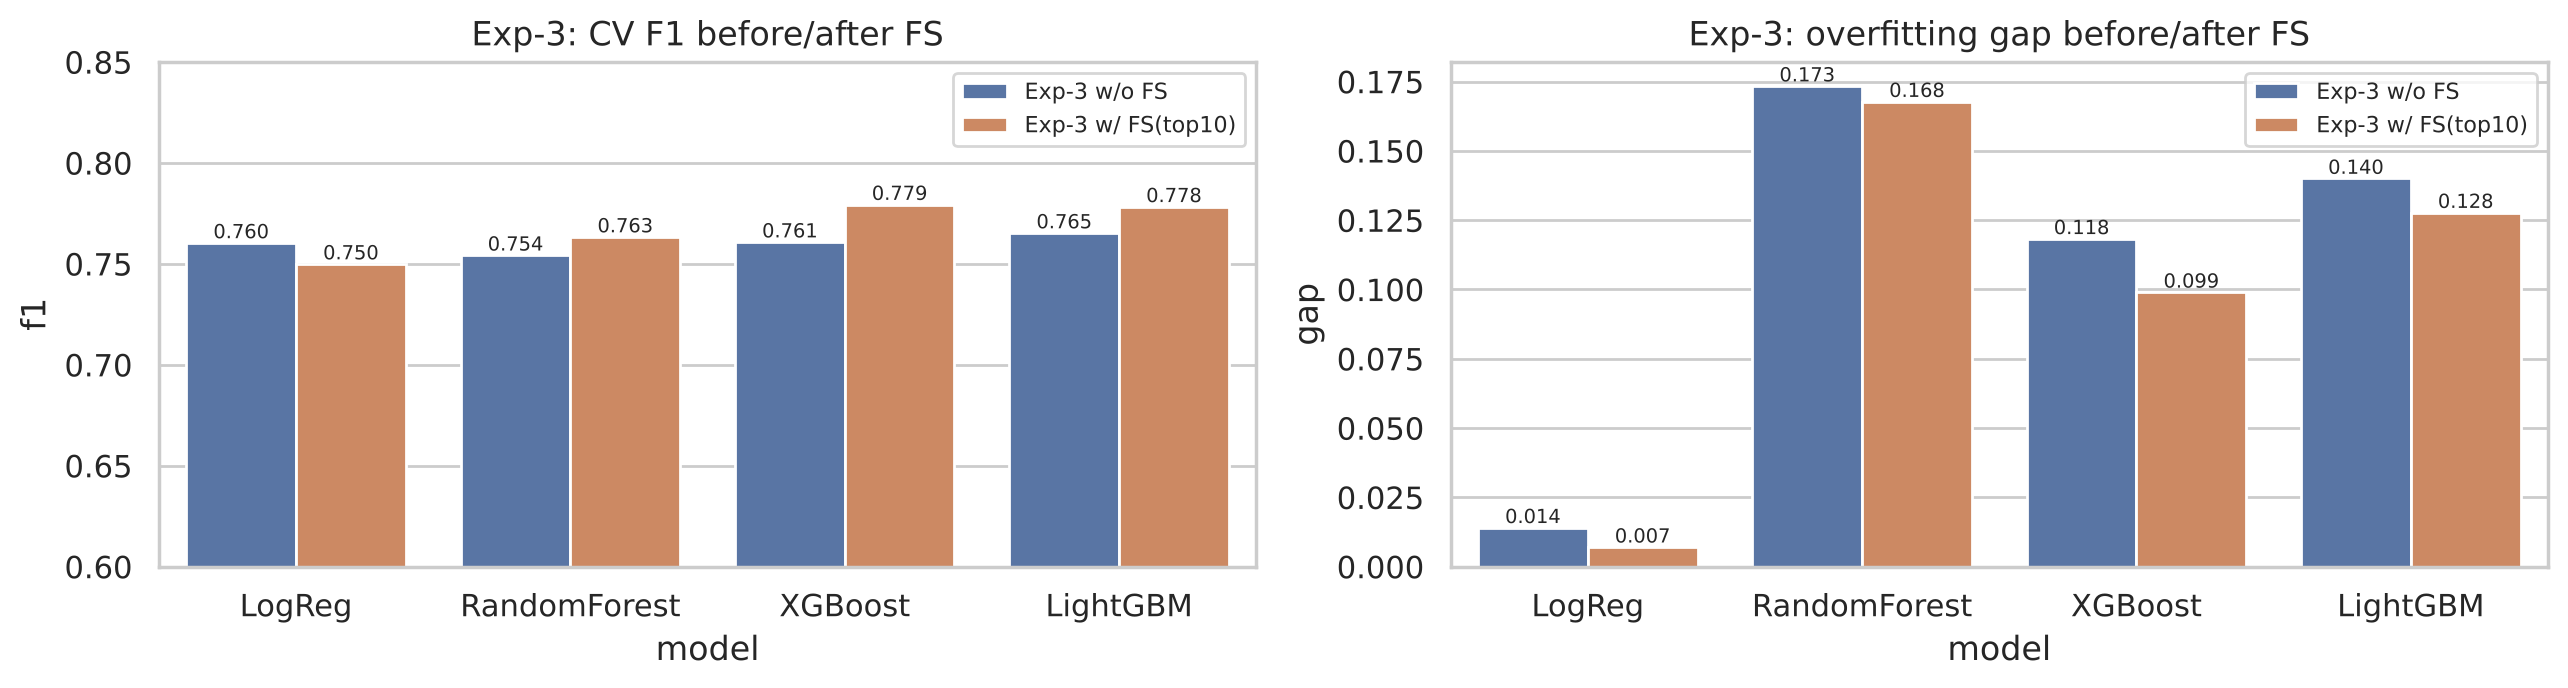

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
sub = fs_res[fs_res.experiment.str.startswith("Exp-3")]
sns.barplot(data=sub, x="model", y="f1", hue="experiment", ax=axes[0]); axes[0].set_ylim(0.6, 0.85); axes[0].set_title("Exp-3: CV F1 before/after FS")
sns.barplot(data=sub, x="model", y="gap", hue="experiment", ax=axes[1]); axes[1].set_title("Exp-3: overfitting gap before/after FS")
for a in axes:
    for c in a.containers: a.bar_label(c, fmt="%.3f", fontsize=7)
    a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/22_fs_before_after.png", dpi=150); plt.show()

## STEP 05 + 5. 실험 비교표 (필수 조합)
| 실험 | 결측치 처리 | 인코딩 | 스케일링 | Feature Selection |
|---|---|---|---|---|
| Base-Raw | 없음 | 없음 | 없음 | 없음 |
| Base-Num | 없음 (결측 없는 수치형 4개) | 없음 (범주형 미사용) | 없음 | 없음 |
| Exp-1 | Mean | One-Hot | Standard | X |
| Exp-2 | Median | Label | MinMax | O (상위 10) |
| Exp-3 | Most Frequent | One-Hot | Robust | O (상위 10) |

**Base는 두 가지로 수행한다.**
- **Base-Raw (과제표 그대로)**: 원본 7개 컬럼(Pclass, Sex, Age, SibSp, Parch, Fare, Embarked)을 결측·문자열 그대로 입력. 결측치 처리·인코딩·스케일링·변수 선택 모두 없음. 결측과 범주형을 자체 처리하는 XGBoost/LightGBM만 학습 가능하고, Logistic Regression/Random Forest는 오류로 학습 불가 → 오류 메시지를 그대로 기록
- **Base-Num (4개 모델 비교용)**: 전처리 없이 4개 모델 모두 학습 가능한 유일한 입력인 **결측 없는 원본 수치형 4개 컬럼(Pclass, SibSp, Parch, Fare)** 만 사용

Exp-1~3은 파생 변수를 모두 포함한다.

In [12]:
CONFIGS = {
    "Base-Num": None,
    "Exp-1": dict(impute="mean", encode="onehot", scale="standard", fs_k=None),
    "Exp-2": dict(impute="median", encode="label", scale="minmax", fs_k=K),
    "Exp-3": dict(impute="most_frequent", encode="onehot", scale="robust", fs_k=K),
}


def make(exp, model):
    return build_base_pipeline(model) if CONFIGS[exp] is None else build_pipeline(model, **CONFIGS[exp])


main_rows = []
# --- Base-Raw: 원본 그대로 (전처리 없음) ---
Xr_train, Xr_test = to_raw(X_train), to_raw(X_test)
base_raw_errors = {}
for m in MODEL_NAMES:
    try:
        cvr = cross_validate(get_native_model(m), Xr_train, y_train, cv=CV, scoring=SCORING,
                             return_train_score=True, error_score="raise")
        p = get_native_model(m).fit(Xr_train, y_train)
        pred, proba = p.predict(Xr_test), p.predict_proba(Xr_test)[:, 1]
        r = {k: cvr[f"test_{k}"].mean() for k in SCORING}
        r.update({"f1_std": cvr["test_f1"].std(), "train_acc": cvr["train_accuracy"].mean(),
                  "gap": cvr["train_accuracy"].mean() - cvr["test_accuracy"].mean(),
                  "test_accuracy": accuracy_score(y_test, pred), "test_f1": f1_score(y_test, pred),
                  "test_roc_auc": roc_auc_score(y_test, proba), "note": "학습 가능 (결측·범주형 자체 처리)"})
    except Exception as e:
        msg = str(e).strip().splitlines()[0][:90]
        base_raw_errors[m] = f"{type(e).__name__}: {msg}"
        r = {"note": f"학습 불가 - {type(e).__name__}"}
    r.update({"group": "5 Main", "experiment": "Base-Raw", "model": m})
    main_rows.append(r)
for m, e in base_raw_errors.items():
    print(f"[Base-Raw] {m} 학습 불가 -> {e}")

for exp in CONFIGS:
    for m in MODEL_NAMES:
        r = cv_eval(make(exp, m))
        p = make(exp, m).fit(X_train, y_train)               # train 전체로 학습 → test 평가
        pred, proba = p.predict(X_test), p.predict_proba(X_test)[:, 1]
        r.update({"group": "5 Main", "experiment": exp, "model": m,
                  "test_accuracy": accuracy_score(y_test, pred), "test_f1": f1_score(y_test, pred),
                  "test_roc_auc": roc_auc_score(y_test, proba)})
        main_rows.append(r)
main = pd.DataFrame(main_rows)
all_rows.extend(main_rows)
main["note"] = main["note"].fillna("")
main_tbl = main[["experiment", "model", "accuracy", "precision", "recall", "f1", "f1_std", "roc_auc",
                 "gap", "test_accuracy", "test_f1", "test_roc_auc", "note"]].round(4)
main_tbl.to_csv(f"{RES}/main_comparison.csv", index=False)
main_tbl

[Base-Raw] LogReg 학습 불가 -> ValueError: could not convert string to float: 'male'
[Base-Raw] RandomForest 학습 불가 -> ValueError: could not convert string to float: 'male'


,experiment,model,accuracy,precision,recall,f1,f1_std,roc_auc,gap,test_accuracy,test_f1,test_roc_auc,note
0,Base-Raw,LogReg,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,학습 불가 - ValueError
1,Base-Raw,RandomForest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,학습 불가 - ValueError
2,Base-Raw,XGBoost,0.8272,0.8047,0.7325,0.7658,0.0448,0.8766,0.1071,0.7989,0.7231,0.8167,학습 가능 (결측·범주형 자체 처리)
3,Base-Raw,LightGBM,0.8146,0.7810,0.7178,0.7479,0.0291,0.8702,0.1461,0.7933,0.7176,0.8011,학습 가능 (결측·범주형 자체 처리)
4,Base-Num,LogReg,0.6952,0.6498,0.4542,0.5333,0.0102,0.7060,0.0014,0.6480,0.4615,0.6742,
5,Base-Num,RandomForest,0.7247,0.6683,0.5605,0.6091,0.0405,0.7507,0.1373,0.5922,0.4748,0.6470,
6,Base-Num,XGBoost,0.7233,0.6877,0.5127,0.5853,0.0418,0.7754,0.0892,0.6592,0.5120,0.6547,
7,Base-Num,LightGBM,0.7205,0.6765,0.5307,0.5899,0.0430,0.7798,0.0991,0.6313,0.5000,0.6449,
8,Exp-1,LogReg,0.8202,0.7764,0.7546,0.7639,0.0337,0.8674,0.0130,0.8324,0.7761,0.8731,
9,Exp-1,RandomForest,0.8189,0.7792,0.7401,0.7588,0.0378,0.8733,0.1699,0.7821,0.7153,0.8265,


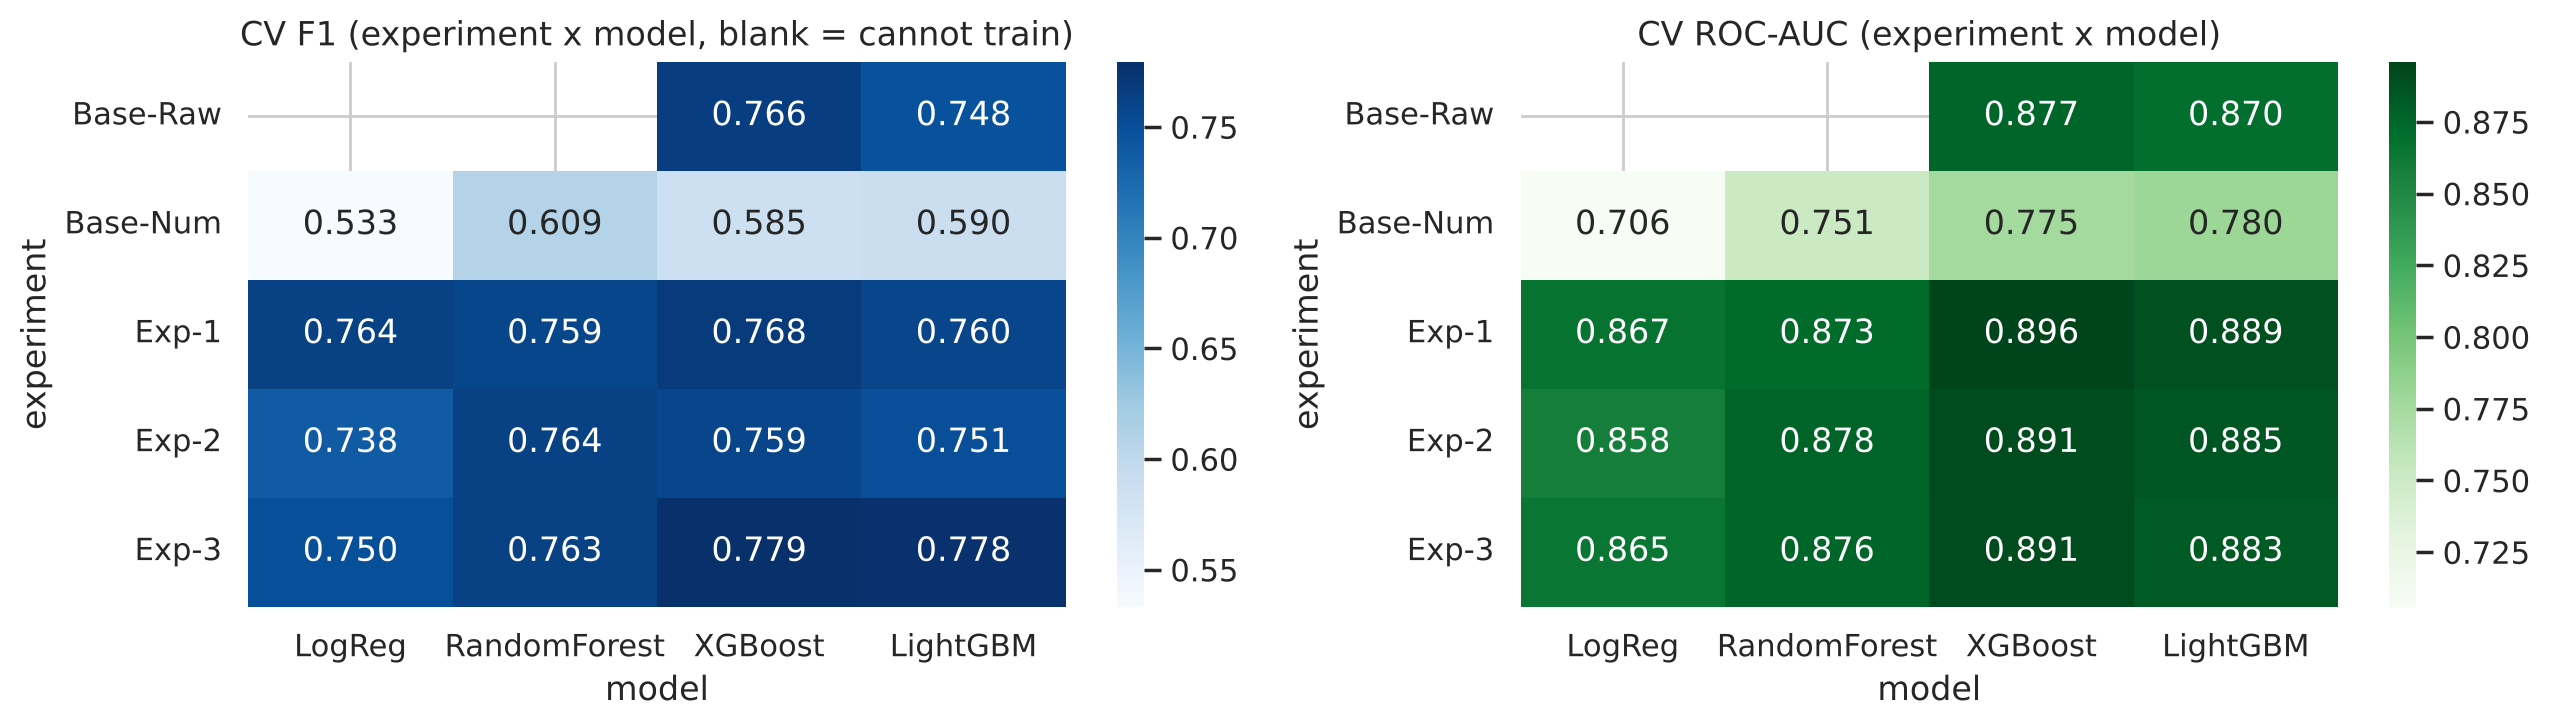

In [13]:
ORDER = ["Base-Raw"] + list(CONFIGS)
piv = main.pivot(index="experiment", columns="model", values="f1").loc[ORDER][MODEL_NAMES]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues", ax=axes[0]); axes[0].set_title("CV F1 (experiment x model, blank = cannot train)")
piv2 = main.pivot(index="experiment", columns="model", values="roc_auc").loc[ORDER][MODEL_NAMES]
sns.heatmap(piv2, annot=True, fmt=".3f", cmap="Greens", ax=axes[1]); axes[1].set_title("CV ROC-AUC (experiment x model)")
plt.tight_layout(); plt.savefig(f"{FIG}/30_main_heatmap.png", dpi=150); plt.show()

## 가산점: GridSearchCV 하이퍼파라미터 튜닝 (Pipeline 전체를 대상으로)
전처리 옵션(결측치 대체 전략, 변수 선택 개수)과 모델 하이퍼파라미터를 **함께** 탐색한다.

In [14]:
grids = {
    "RandomForest": {"pre__num__imp__strategy": ["mean", "median"], "fs__max_features": [8, 10, 15],
                     "clf__max_depth": [4, 6, 8, None],
                     "clf__min_samples_leaf": [1, 3, 5]},
    "XGBoost": {"pre__num__imp__strategy": ["mean", "median"], "fs__max_features": [8, 10, 15],
                "clf__n_estimators": [200, 400], "clf__max_depth": [2, 3, 4, 5],
                "clf__learning_rate": [0.03, 0.1]},
    "LogReg": {"pre__num__imp__strategy": ["mean", "median"], "fs__max_features": [8, 10, 15, 20],
               "clf__C": [0.01, 0.1, 0.3, 1, 3, 10]},
}
tuned, gs_rows = {}, []
for m, g in grids.items():
    t0 = time.time()
    gs = GridSearchCV(build_pipeline(m, impute="most_frequent", encode="onehot", scale="robust", fs_k=K),
                      g, cv=CV, scoring="f1", n_jobs=-1).fit(X_train, y_train)
    tuned[m] = gs.best_estimator_
    pred, proba = gs.predict(X_test), gs.predict_proba(X_test)[:, 1]
    gs_rows.append({"model": m, "n_candidates": len(gs.cv_results_["params"]), "best_cv_f1": gs.best_score_,
                    "test_accuracy": accuracy_score(y_test, pred), "test_precision": precision_score(y_test, pred),
                    "test_recall": recall_score(y_test, pred), "test_f1": f1_score(y_test, pred),
                    "test_roc_auc": roc_auc_score(y_test, proba), "best_params": gs.best_params_,
                    "sec": round(time.time() - t0, 1)})
gs_tbl = pd.DataFrame(gs_rows)
gs_tbl.round(4).to_csv(f"{RES}/gridsearch_results.csv", index=False)
gs_tbl.round(4)

,model,n_candidates,best_cv_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,best_params,sec
0,RandomForest,72,0.7939,0.7877,0.7541,0.6667,0.7077,0.8456,"{'clf__max_depth': 8, 'clf__min_samples_leaf':...",91.4
1,XGBoost,96,0.7790,0.8101,0.7612,0.7391,0.7500,0.8322,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",71.9
2,LogReg,48,0.7697,0.8156,0.7812,0.7246,0.7519,0.8610,"{'clf__C': 1, 'fs__max_features': 15, 'pre__nu...",31.1


In [15]:
for r in gs_rows:
    print(r["model"], r["best_params"])

RandomForest {'clf__max_depth': 8, 'clf__min_samples_leaf': 1, 'fs__max_features': 8, 'pre__num__imp__strategy': 'median'}
XGBoost {'clf__learning_rate': 0.1, 'clf__max_depth': 4, 'clf__n_estimators': 200, 'fs__max_features': 10, 'pre__num__imp__strategy': 'mean'}
LogReg {'clf__C': 1, 'fs__max_features': 15, 'pre__num__imp__strategy': 'mean'}


## 최종 모델 테스트셋 평가: Base-Num vs 튜닝 모델 (Confusion Matrix, ROC Curve)

CV 기준 최종 모델: RandomForest


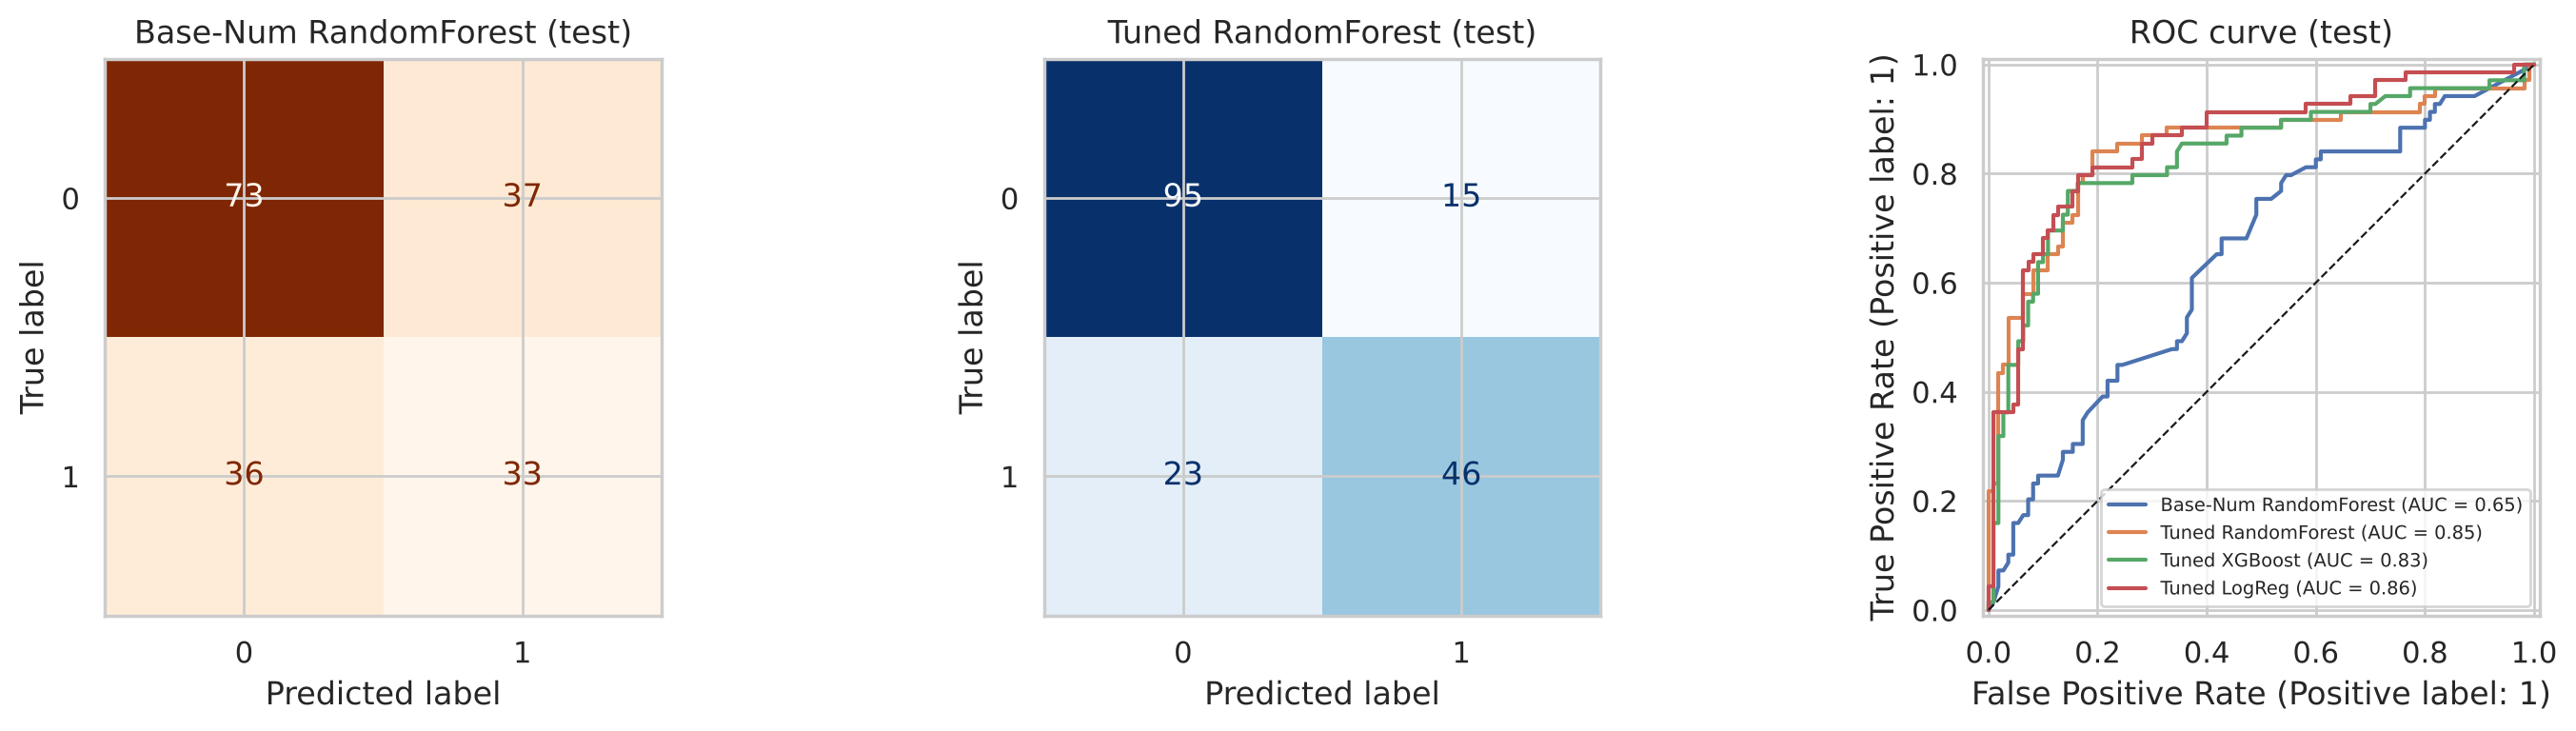

In [16]:
best_name = gs_tbl.sort_values("best_cv_f1", ascending=False).iloc[0]["model"]   # CV 기준으로 선택 (test로 고르지 않음)
best = tuned[best_name]
base_rf = build_base_pipeline(best_name).fit(X_train, y_train)
print("CV 기준 최종 모델:", best_name)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_estimator(base_rf, X_test, y_test, ax=axes[0], colorbar=False, cmap="Oranges")
axes[0].set_title(f"Base-Num {best_name} (test)")
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, ax=axes[1], colorbar=False, cmap="Blues")
axes[1].set_title(f"Tuned {best_name} (test)")
RocCurveDisplay.from_estimator(base_rf, X_test, y_test, ax=axes[2], name=f"Base-Num {best_name}")
for m, est in tuned.items():
    RocCurveDisplay.from_estimator(est, X_test, y_test, ax=axes[2], name=f"Tuned {m}")
axes[2].plot([0, 1], [0, 1], "k--", lw=0.8); axes[2].set_title("ROC curve (test)"); axes[2].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(f"{FIG}/40_final_test_eval.png", dpi=150); plt.show()

## 가산점: Feature Importance 시각화 고도화 (MDI vs Permutation) + SHAP

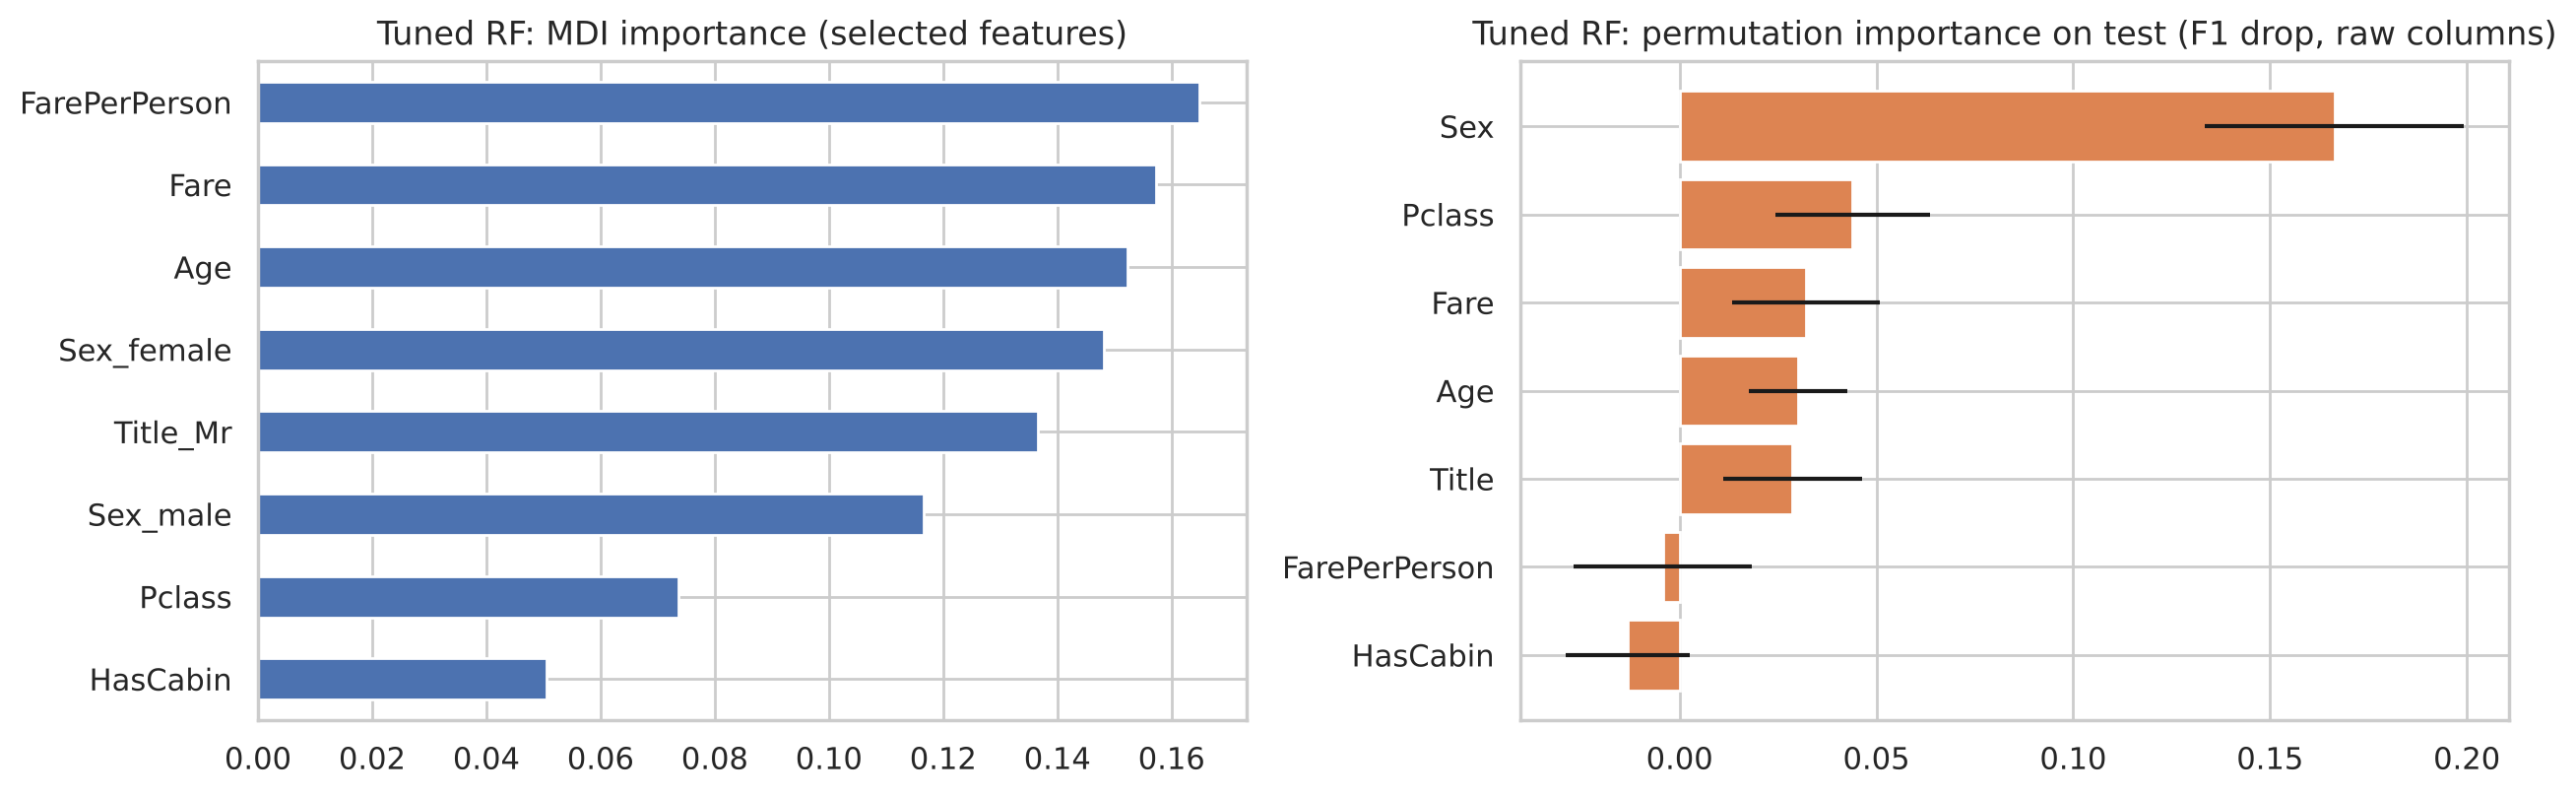

Sex              0.1664
Pclass           0.0439
Fare             0.0320
Age              0.0301
Title            0.0286
FarePerPerson   -0.0043
HasCabin        -0.0133
dtype: float64


In [17]:
rf_t = tuned["RandomForest"]
names_sel = [n.split("__", 1)[1] for n in rf_t[:-1].get_feature_names_out()]
mdi = pd.Series(rf_t[-1].feature_importances_, index=names_sel)
perm = permutation_importance(rf_t, X_test, y_test, scoring="f1", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
# permutation은 원본 입력 컬럼 단위로 계산됨
perm_s = pd.Series(perm.importances_mean, index=X_test.columns)
perm_s = perm_s[perm_s.abs() > 1e-9].sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
mdi.sort_values().plot.barh(ax=axes[0], color="#4C72B0"); axes[0].set_title("Tuned RF: MDI importance (selected features)")
axes[1].barh(perm_s.index, perm_s.values, xerr=perm.importances_std[[list(X_test.columns).index(c) for c in perm_s.index]], color="#DD8452")
axes[1].set_title("Tuned RF: permutation importance on test (F1 drop, raw columns)")
plt.tight_layout(); plt.savefig(f"{FIG}/50_importance_mdi_vs_perm.png", dpi=150); plt.show()
print(perm_s.sort_values(ascending=False).round(4))

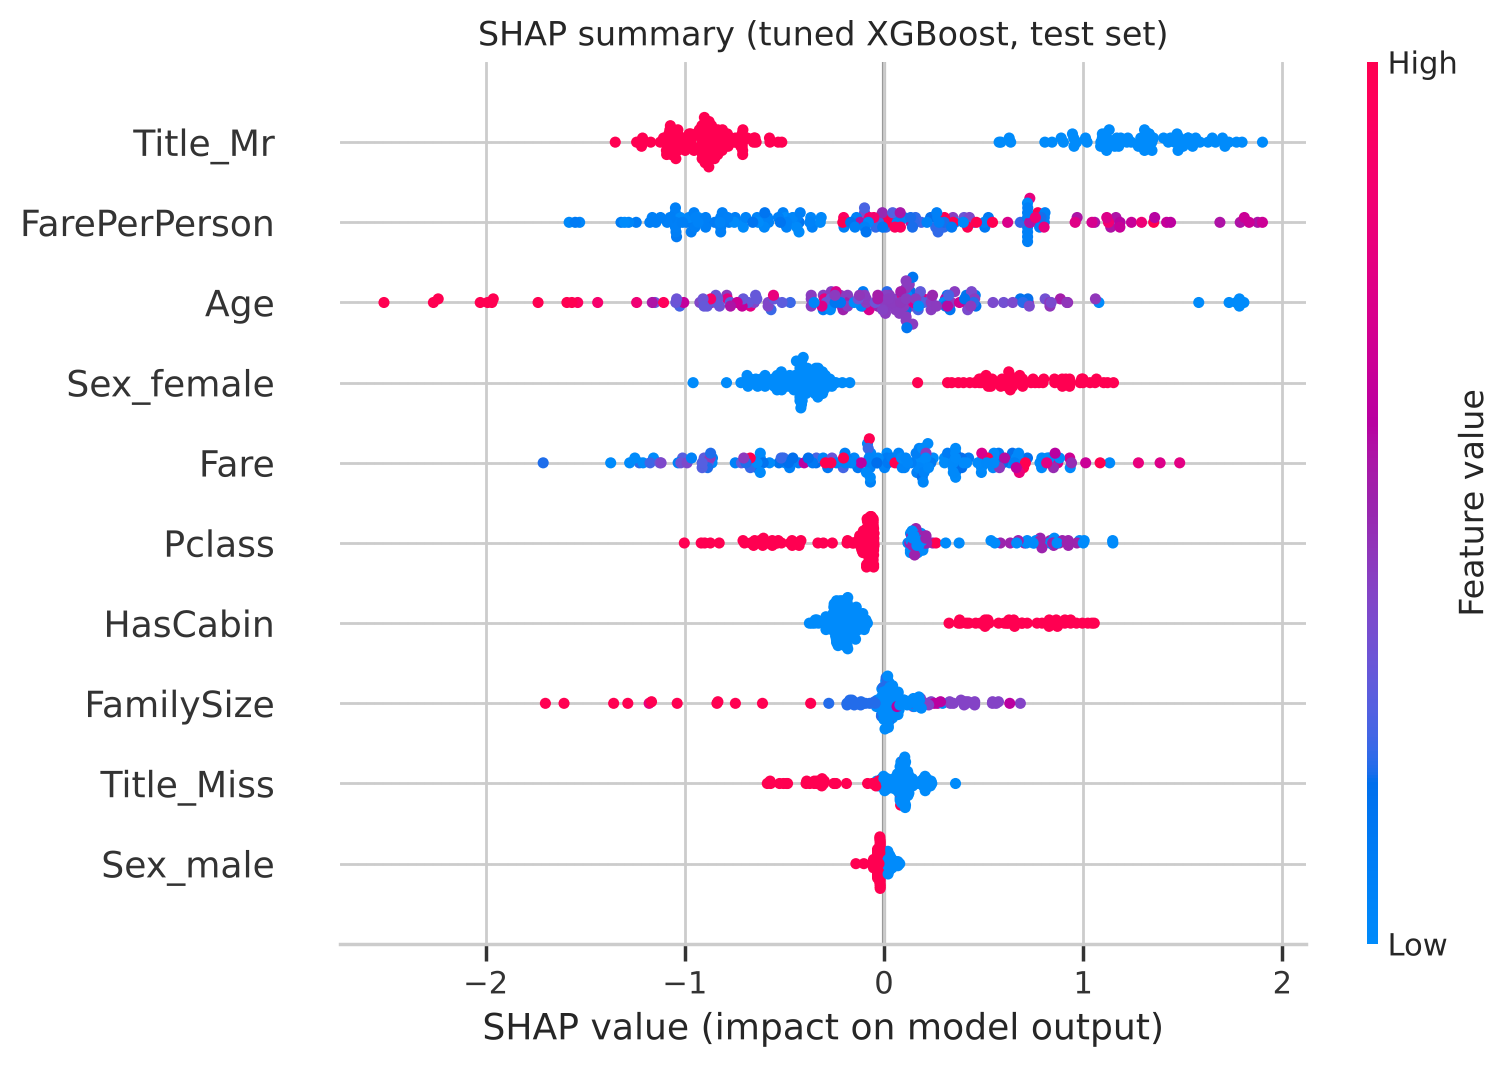

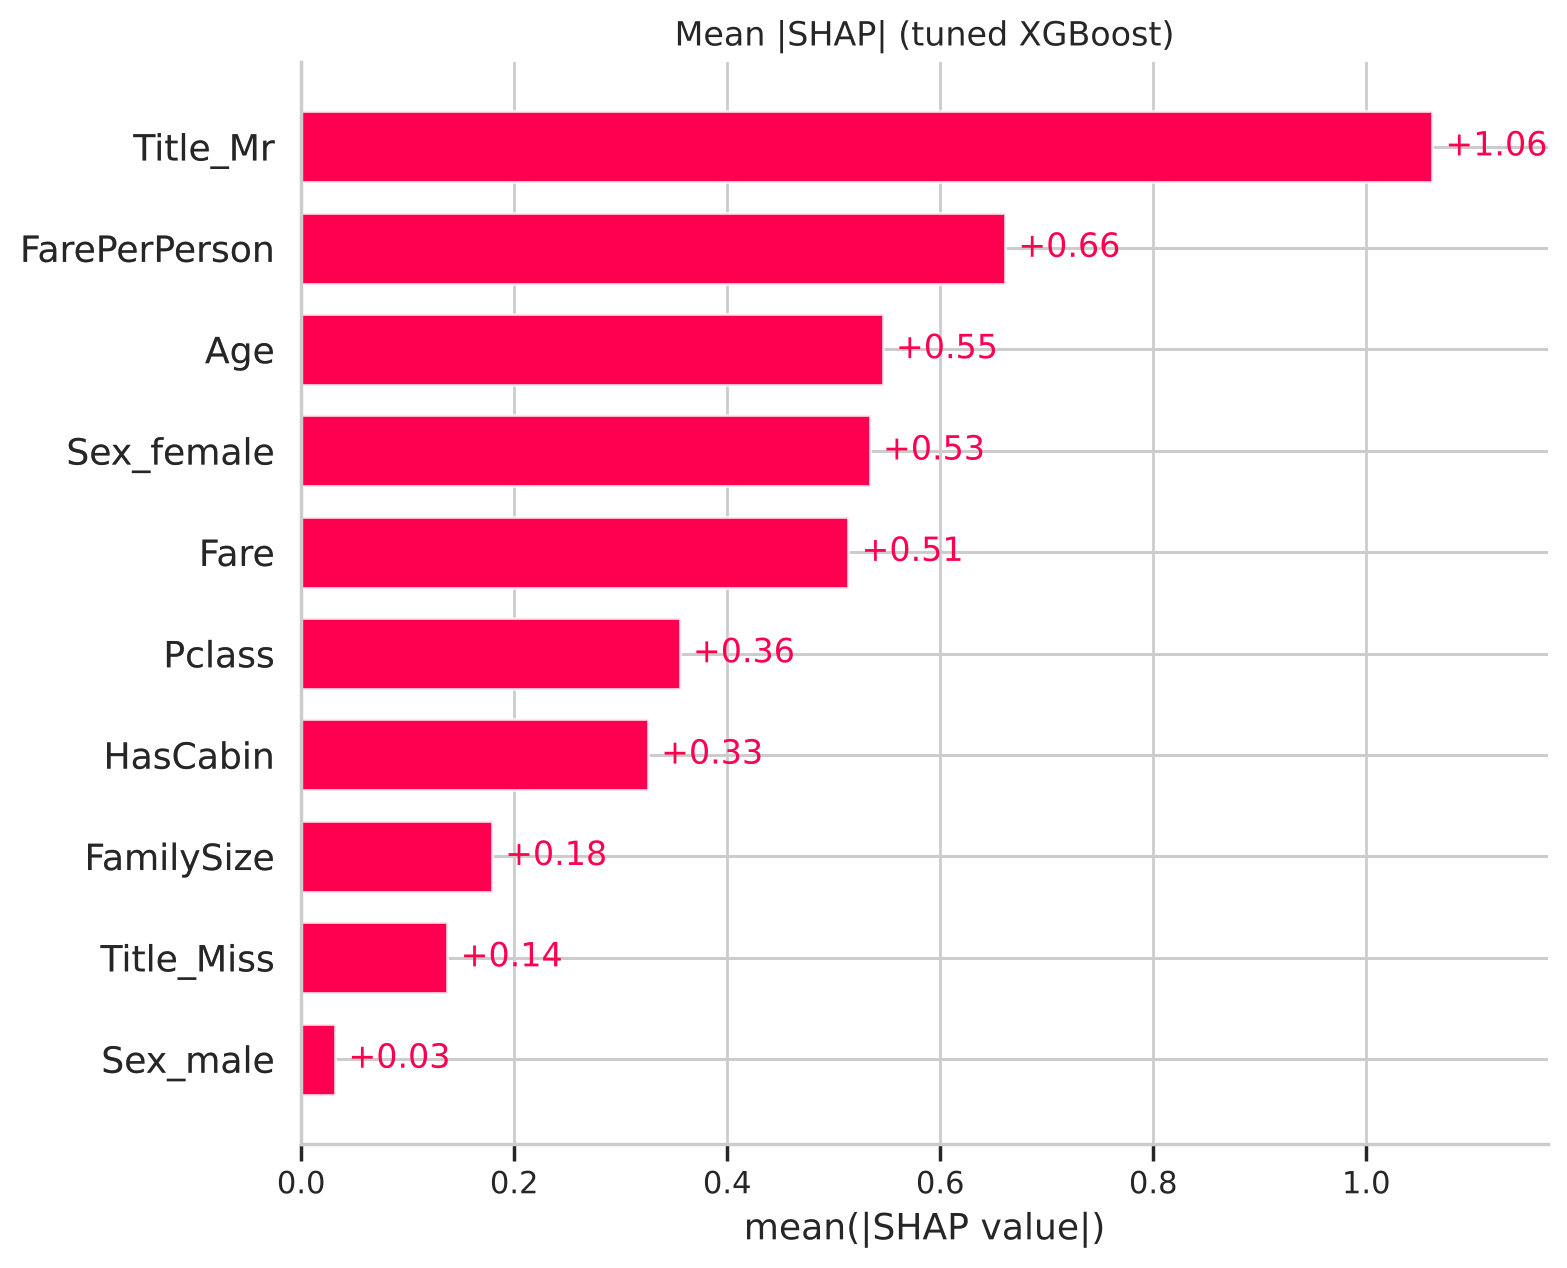

Title_Mr         1.0618
FarePerPerson    0.6608
Age              0.5459
Sex_female       0.5337
Fare             0.5136
Pclass           0.3552
HasCabin         0.3254
FamilySize       0.1789
Title_Miss       0.1372
Sex_male         0.0318
dtype: float32


In [18]:
import shap
xgb_t = tuned["XGBoost"]
Z_test = xgb_t[:-1].transform(X_test)
z_names = [n.split("__", 1)[1] for n in xgb_t[:-1].get_feature_names_out()]
Z_df = pd.DataFrame(Z_test, columns=z_names)
explainer = shap.TreeExplainer(xgb_t[-1])
sv = explainer(Z_df)
plt.figure(); shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("SHAP summary (tuned XGBoost, test set)"); plt.tight_layout()
plt.savefig(f"{FIG}/51_shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()
plt.figure(); shap.plots.bar(sv, max_display=12, show=False)
plt.title("Mean |SHAP| (tuned XGBoost)"); plt.tight_layout()
plt.savefig(f"{FIG}/52_shap_bar.png", dpi=150, bbox_inches="tight"); plt.show()
shap_imp = pd.Series(np.abs(sv.values).mean(0), index=z_names).sort_values(ascending=False)
shap_imp.round(4).to_csv(f"{RES}/shap_importance.csv", header=["mean_abs_shap"])
print(shap_imp.round(4))

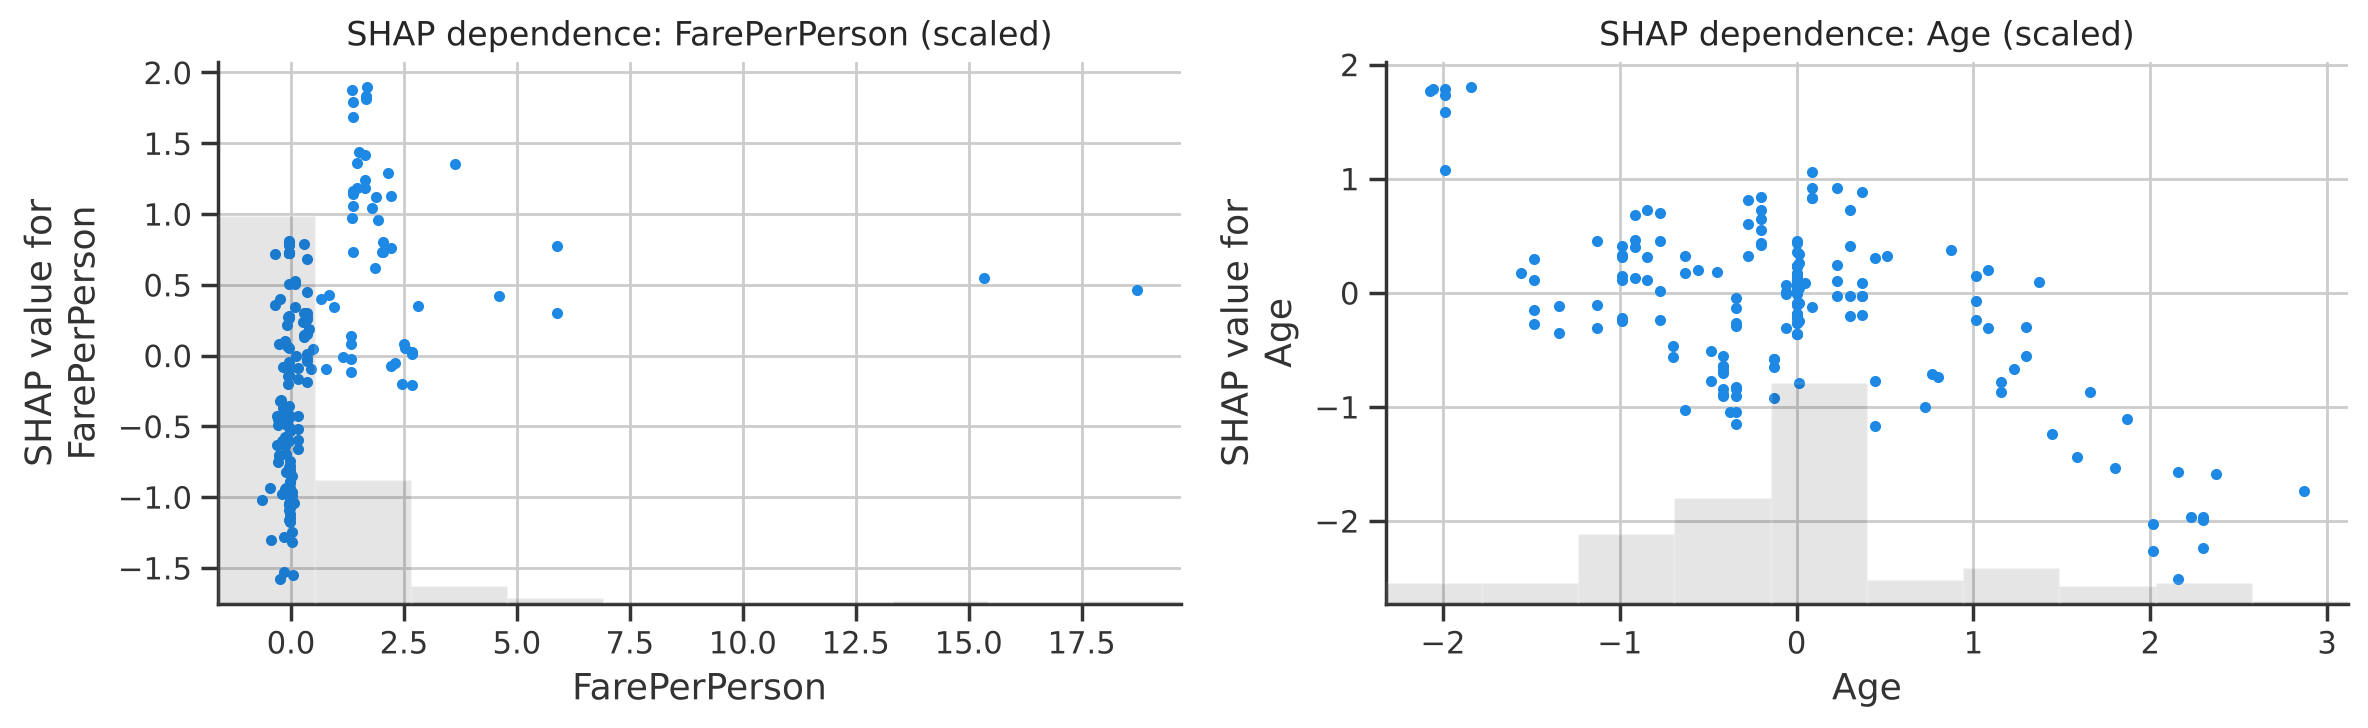

In [19]:
dep = [c for c in ["FarePerPerson", "Age", "Fare", "Pclass"] if c in z_names][:2]
fig, axes = plt.subplots(1, len(dep), figsize=(6 * len(dep), 3.8))
for ax, c in zip(np.atleast_1d(axes), dep):
    shap.plots.scatter(sv[:, c], ax=ax, show=False)
    ax.set_title(f"SHAP dependence: {c} (scaled)")
plt.tight_layout(); plt.savefig(f"{FIG}/53_shap_dependence.png", dpi=150, bbox_inches="tight"); plt.show()

## 전체 실험 결과 저장

In [20]:
all_df = pd.DataFrame(all_rows).drop(columns=["n_features", "note"], errors="ignore")
all_df.round(4).to_csv(f"{RES}/all_results.csv", index=False)
print(all_df.shape)
summary = all_df.groupby(["group", "experiment"], sort=False)[["f1", "roc_auc", "gap"]].mean().round(4)
summary

(88, 18)


f1  roc_auc     gap
group            experiment                                   
3-1 Imputation   Impute=mean           0.7627   0.8813  0.1113
                 Impute=median         0.7653   0.8830  0.1086
                 Impute=most_frequent  0.7622   0.8802  0.1095
                 Impute=dropna         0.7473   0.8690  0.1378
3-2 Encoding     Encode=onehot         0.7627   0.8813  0.1113
                 Encode=label          0.7544   0.8771  0.1126
                 Encode=target         0.7656   0.8821  0.0777
3-3 Scaling      Scale=None            0.7616   0.8809  0.1127
                 Scale=standard        0.7627   0.8813  0.1113
                 Scale=minmax          0.7633   0.8818  0.1122
                 Scale=robust          0.7618   0.8810  0.1127
3-4 Feature Eng. FE=False              0.7446   0.8680  0.1066
                 FE=True               0.7627   0.8813  0.1113
4 Feature Sel.   Exp-3 w/o FS          0.7602   0.8798  0.1114
                 Exp-3 w/ FS(top10)    0.7677   0.8788  0.1004
                 Exp-2 w/o FS          0.7549   0.8789  0.1096
                 Exp-2 w/ FS(top10)    0.7531   0.8781  0.1118
5 Main           Base-Raw              0.7569   0.8734  0.1266
                 Base-Num              0.5794   0.7530  0.0817
                 Exp-1                 0.7627   0.8813  0.1113
                 Exp-2                 0.7531   0.8781  0.1118
                 Exp-3                 0.7677   0.8788  0.1004